# EDA – Riesgo de adiciones en contratos SECOP II (muestra Salud)
**Contexto:** la tabla `SECOP II – Contratos Electrónicos` (jbjy-vk9h) quedó truncada en origen
(devuelve 1.000 filas desde el 24-oct-2026). Este EDA se hace con la descarga previa del sector Salud
(`src/ingest.py`, 800.011 contratos firmados desde 2017) y sigue la tabla de 9 revisiones del reporte.

**Entradas.** El mismo cuaderno se ejecuta con dos entradas, según las variables de entorno `EDA_TAG` y `EDA_INPUT`:
`salud` (descarga previa, 800 mil contratos; por defecto) y `snapshot` (instantánea de 1.000 filas de la tabla tal como
está hoy, todos los sectores). Con la instantánea, los umbrales de tamaño mínimo se reducen y los resultados son solo indicativos.

**Objetivo `y`** = 1 si el contrato registró adición en **valor** (tabla Adiciones, tipo "Adicion en el valor")
**o** en **tiempo** (`dias_adicionados > 0`).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os
from pathlib import Path
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

ROOT = Path("..")
TAG = os.environ.get("EDA_TAG", "salud")
INPUT = os.environ.get("EDA_INPUT", "contratos_salud.csv")
RAW, FIG = ROOT / "data/raw", ROOT / "reports" / ("figures" if TAG == "salud" else f"figures_{TAG}")
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
num = lambda s: pd.to_numeric(s, errors="coerce")

c = pd.read_csv(RAW / INPUT, low_memory=False)
a = pd.read_csv(RAW / "adiciones_valor.csv")
if TAG == "obra":   # SECOP Integrado: se renombran las columnas al esquema de Contratos Electrónicos
    c = c.rename(columns={"numero_del_contrato": "id_contrato", "fecha_de_firma_del_contrato": "fecha_de_firma",
                          "valor_contrato": "valor_del_contrato", "departamento_entidad": "departamento",
                          "modalidad_de_contrataci_n": "modalidad_de_contratacion", "nombre_de_la_entidad": "nombre_entidad",
                          "estado_del_proceso": "estado_contrato", "nivel_entidad": "orden", "tipo_documento_proveedor": "tipodocproveedor",
                          "fecha_inicio_ejecuci_n": "fecha_de_inicio_del_contrato", "fecha_fin_ejecuci_n": "fecha_de_fin_del_contrato"})
    PRORROGA = set(pd.read_csv(RAW / "adic_senal_prorroga.csv", usecols=["id_contrato"]).id_contrato)  # señal aproximada (texto)
SMALL = len(c) < 5_000   # con muestras pequeñas se bajan los umbrales mínimos de tamaño
MIN_DEP, MIN_ENT, N_DEC = (15, 5, 5) if SMALL else ((50, 30, 10) if len(c) < 200_000 else (500, 200, 10))
print(TAG, INPUT, c.shape, a.shape, "| muestra pequeña:", SMALL)

obra contratos_obra_integrado.csv (78824, 17) (257152, 4) | muestra pequeña: False


## 0. Construcción de la variable objetivo y variables al momento de la firma

In [2]:
c["fecha_firma"] = pd.to_datetime(c.fecha_de_firma, errors="coerce")
c["anio"], c["mes"] = c.fecha_firma.dt.year.astype("Int64"), c.fecha_firma.dt.month.astype("Int64")
c["valor"] = num(c.valor_del_contrato)
if TAG == "obra":
    c["plazo_dias"] = (pd.to_datetime(c.fecha_de_fin_del_contrato, errors="coerce") - pd.to_datetime(c.fecha_de_inicio_del_contrato, errors="coerce")).dt.days
else:
    dur = c.duraci_n_del_contrato.str.extract(r"(\d+)\s*([A-Za-z])")
    mult = {"D": 1, "M": 30, "A": 365, "S": 7, "H": 1 / 24}
    c["plazo_dias"] = num(dur[0]) * dur[1].map(mult)
    c["saldo_cdp_n"] = num(c.saldo_cdp)

n_adic = a.groupby("id_contrato").size()
c["n_adic_valor"] = c.id_contrato.map(n_adic).fillna(0).astype(int)
c["dias_adic"] = num(c.dias_adicionados).fillna(0) if "dias_adicionados" in c else 0
c["y_valor"] = (c.n_adic_valor > 0).astype(int)
c["y_tiempo"] = (c.id_contrato.isin(PRORROGA) if TAG == "obra" else c.dias_adic > 0).astype(int)  # obra: señal aproximada por texto de la descripción
c["y"] = (c.y_valor | c.y_tiempo).astype(int)

print("Contratos sin fecha de firma válida:", c.fecha_firma.isna().sum())
print("dias_adicionados > 5 años (posible error de digitación):", (c.dias_adic > 1825).sum())

Contratos sin fecha de firma válida: 0
dias_adicionados > 5 años (posible error de digitación): 0


## 1. Tasa global de adición (balance de clases) y madurez de la muestra

Contratos 2017-2025: 78,824 | tasa y=56.9% | valor=10.8% | tiempo=52.4%
      contratos     y  valor  tiempo
anio                                
2019       2617 0.479  0.253   0.365
2020       3380 0.621  0.185   0.547
2021       6545 0.586  0.116   0.534
2022       8390 0.591  0.107   0.552
2023      12982 0.550  0.095   0.512
2024      18740 0.595  0.097   0.552
2025      26170 0.552  0.096   0.510


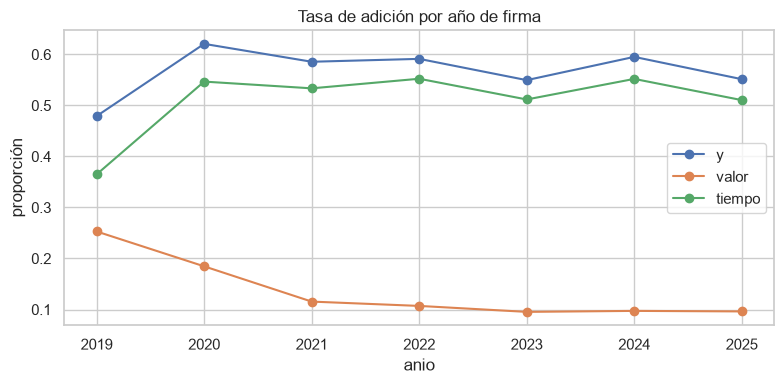

In [3]:
df = c[c.anio.between(2017, 2025)].copy()   # 2026 se excluye: contratos aún sin tiempo de recibir adiciones
print(f"Contratos 2017-2025: {len(df):,} | tasa y={df.y.mean():.1%} | valor={df.y_valor.mean():.1%} | tiempo={df.y_tiempo.mean():.1%}")
by_year = df.groupby("anio").agg(contratos=("y", "size"), y=("y", "mean"), valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean"))
print(by_year.to_string())
ax = by_year[["y", "valor", "tiempo"]].plot(marker="o", figsize=(8, 4), title="Tasa de adición por año de firma")
ax.set_ylabel("proporción"); plt.tight_layout(); plt.savefig(FIG / "01_tasa_por_anio.png", dpi=150); plt.show()

In [4]:
by_state = df.groupby("estado_contrato").agg(contratos=("y", "size"), y=("y", "mean")).sort_values("contratos", ascending=False)
print(by_state.to_string())
print("El estado depende del desenlace ('Modificado' ya implica modificación): no debe usarse para definir la muestra ni como variable.")

                 contratos     y
estado_contrato                 
Modificado           32586 0.751
terminado            13517 0.443
En ejecución         12134 0.281
Suspendido            7674 0.793
Activo                5662 0.371
Aprobado              3786 0.407
Cerrado               3317 0.365
cedido                 138 0.565
Cancelado               10 0.100
El estado depende del desenlace ('Modificado' ya implica modificación): no debe usarse para definir la muestra ni como variable.


## 2. Nulos / valores no definidos en variables de firma

valor                           0.000
tipo_de_contrato                0.000
modalidad_de_contratacion       0.000
departamento                    0.800
plazo_dias                     11.000
fecha_de_inicio_del_contrato   11.000
tipodocproveedor               57.700


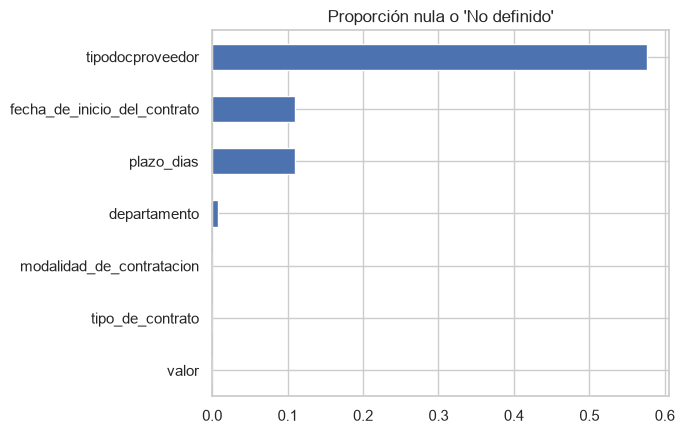

Ofertas, garantías y proveedores (tablas aparte) no se descargaron en esta muestra: ver limitaciones.


In [5]:
firma_vars = ["valor", "plazo_dias", "modalidad_de_contratacion", "tipo_de_contrato", "departamento", "origen_de_los_recursos",
              "condiciones_de_entrega", "tipodocproveedor", "es_pyme", "habilita_pago_adelantado", "codigo_proveedor",
              "fecha_de_inicio_del_contrato", "saldo_cdp_n", "justificacion_modalidad_de"]
undef = lambda s: s.isna() | s.astype(str).str.strip().str.lower().isin(["no definido", "no definida", "sin descripcion", "nan", "no d"])
nul = pd.Series({v: undef(df[v]).mean() for v in firma_vars if v in df}).sort_values()
print((nul * 100).round(1).to_string())
nul.plot.barh(figsize=(7, 4.5), title="Proporción nula o 'No definido'"); plt.tight_layout(); plt.savefig(FIG / "02_nulos.png", dpi=150); plt.show()
print("Ofertas, garantías y proveedores (tablas aparte) no se descargaron en esta muestra: ver limitaciones.")

## 3. Variación por departamento

                                         contratos     y
departamento                                            
Vichada                                        110 0.627
Guaviare                                        93 0.634
Cundinamarca                                  4723 0.642
Meta                                          1934 0.650
Distrito Capital de Bogotá                   22411 0.672
Magdalena                                     1467 0.675
San Andrés Providencia y Santa Catalina        247 0.713
Risaralda                                     1316 0.724
                    contratos     y
departamento                       
Arauca                    827 0.244
Caquetá                  1000 0.248
Huila                    1851 0.379
Norte de Santander       2064 0.416
Antioquia                7963 0.420
Rango de tasa entre departamentos (n>=50): 24.4% - 72.4%


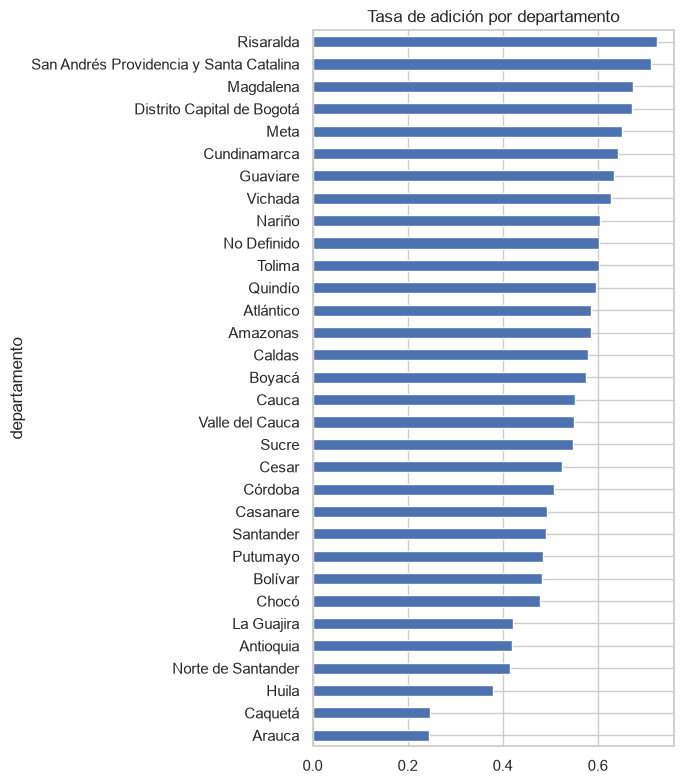

In [6]:
dep = df.groupby("departamento").agg(contratos=("y", "size"), y=("y", "mean")).query("contratos >= @MIN_DEP").sort_values("y")
print(dep.tail(8).to_string()); print(dep.head(5).to_string())
print(f"Rango de tasa entre departamentos (n>={MIN_DEP}): {dep.y.min():.1%} - {dep.y.max():.1%}")
dep.y.plot.barh(figsize=(7, 8), title="Tasa de adición por departamento"); plt.tight_layout(); plt.savefig(FIG / "03_departamento.png", dpi=150); plt.show()

## 4. Modalidad de contratación y tipo de contrato

                                                             contratos     y  valor  tiempo
modalidad_de_contratacion                                                                  
Selección Abreviada de Menor Cuantía                             21689 0.578  0.145   0.510
Licitación pública Obra Publica                                  19869 0.745  0.113   0.720
Contratación directa                                             15442 0.517  0.033   0.506
Mínima cuantía                                                   11939 0.372  0.147   0.277
Contratación régimen especial                                     3392 0.476  0.082   0.435
Contratación régimen especial (con ofertas)                       3192 0.557  0.086   0.533
Contratación Directa (con ofertas)                                2371 0.461  0.066   0.434
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes        613 0.723  0.189   0.682
Licitación pública                                                 304 0.586  0.

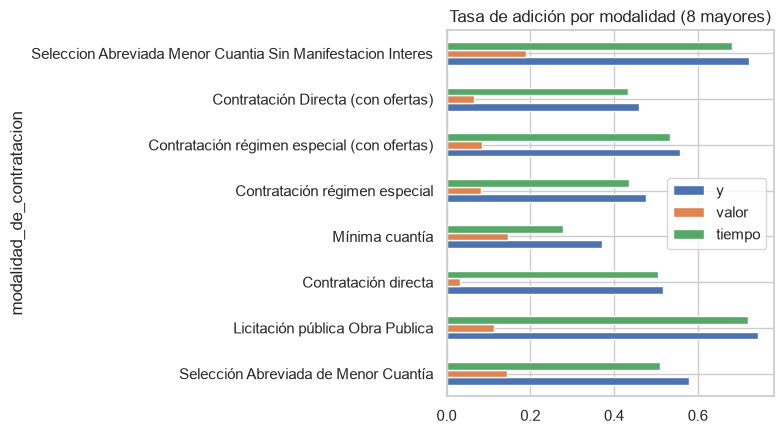

In [7]:
mod = df.groupby("modalidad_de_contratacion").agg(contratos=("y", "size"), y=("y", "mean"), valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean")).sort_values("contratos", ascending=False)
print(mod.to_string())
print("Categorías con < 1.000 contratos:", (mod.contratos < 1000).sum(), "de", len(mod))
tip = df.groupby("tipo_de_contrato").agg(contratos=("y", "size"), y=("y", "mean")).sort_values("contratos", ascending=False).head(10)
print(tip.to_string())
mod.head(8)[["y", "valor", "tiempo"]].plot.barh(figsize=(8, 4.5), title="Tasa de adición por modalidad (8 mayores)")
plt.tight_layout(); plt.savefig(FIG / "04_modalidad.png", dpi=150); plt.show()

## 5. Valor y plazo vs adición

dec_valor
1    0.229
2    0.377
3    0.426
4    0.548
5    0.564
6    0.650
7    0.747
8    0.764
9    0.787
10   0.821


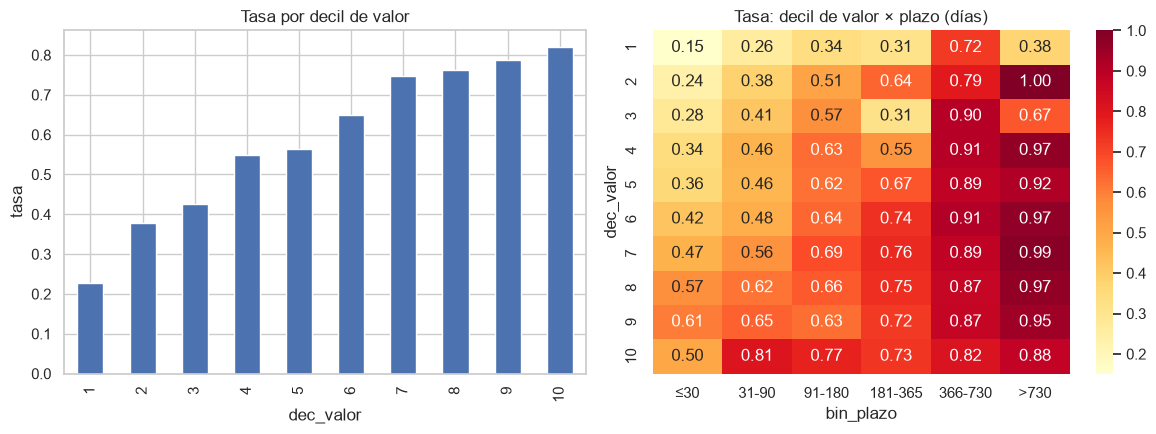

Spearman valor~y: 0.377 | plazo~y: 0.401


In [8]:
d5 = df[(df.valor > 0) & (df.plazo_dias > 0) & (df.plazo_dias <= 3650)].copy()
d5["dec_valor"] = pd.qcut(d5.valor, N_DEC, labels=False, duplicates="drop") + 1
d5["bin_plazo"] = pd.cut(d5.plazo_dias, [0, 30, 90, 180, 365, 730, 3650], labels=["≤30", "31-90", "91-180", "181-365", "366-730", ">730"])
rate_v = d5.groupby("dec_valor").y.mean()
print(rate_v.round(3).to_string())
hm = d5.pivot_table(index="dec_valor", columns="bin_plazo", values="y", aggfunc="mean", observed=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
rate_v.plot.bar(ax=ax[0], title="Tasa por decil de valor"); ax[0].set_ylabel("tasa")
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax[1]); ax[1].set_title("Tasa: decil de valor × plazo (días)")
plt.tight_layout(); plt.savefig(FIG / "05_valor_plazo.png", dpi=150); plt.show()
print("Spearman valor~y:", round(d5[["valor", "y"]].corr("spearman").iloc[0, 1], 3), "| plazo~y:", round(d5[["plazo_dias", "y"]].corr("spearman").iloc[0, 1], 3))

## 6. Estacionalidad (mes de firma)

mes            1         2         3         4         5         6         7         8         9          10         11         12
contratos 971.000 1,515.000 2,271.000 3,211.000 4,800.000 5,680.000 5,995.000 6,624.000 8,669.000 10,265.000 13,075.000 15,748.000
y           0.585     0.565     0.516     0.536     0.553     0.539     0.586     0.582     0.569      0.539      0.577      0.601


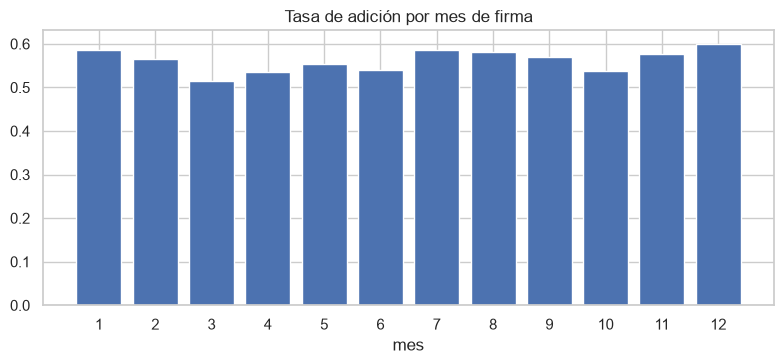

Mes con mayor/menor tasa: 12 (60.1%) / 3 (51.6%)


In [9]:
mes = df.groupby("mes").agg(contratos=("y", "size"), y=("y", "mean"))
print(mes.T.to_string())
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.bar(mes.index, mes.y); ax.set_xticks(range(1, 13)); ax.set_title("Tasa de adición por mes de firma"); ax.set_xlabel("mes")
plt.tight_layout(); plt.savefig(FIG / "06_mes.png", dpi=150); plt.show()
print(f"Mes con mayor/menor tasa: {mes.y.idxmax()} ({mes.y.max():.1%}) / {mes.y.idxmin()} ({mes.y.min():.1%})")

## 7. Concentración por entidad

Entidades: 2,499. Top 10 concentran 24.4% de los contratos con adición; top 100: 52.8%
                                                                  contratos  adic     y
nombre_entidad                                                                         
INVIAS                                                                 6068  5144 0.848
INSTITUTO DE INFRAESTRUCTURA Y CONCESIONES DE CUNDINAMARCA             2414  1159 0.480
INSTITUTO DE CAMINOS Y CONSTRUCCIONES DE CUNDINAMARCA - ICCU           1558  1055 0.677
AEROCIVIL                                                              2109   994 0.471
GOBERNACION DEL MAGDALENA                                               863   639 0.740
MUNICIPIO DE MANIZALES                                                  625   454 0.726
GOBIERNO DEPARTAMENTAL                                                  629   437 0.695
AGENCIA PARA LA INFRAESTRUCTURA DEL META                                522   396 0.759
INSTITUTO DE DESARROLLO URBANO   

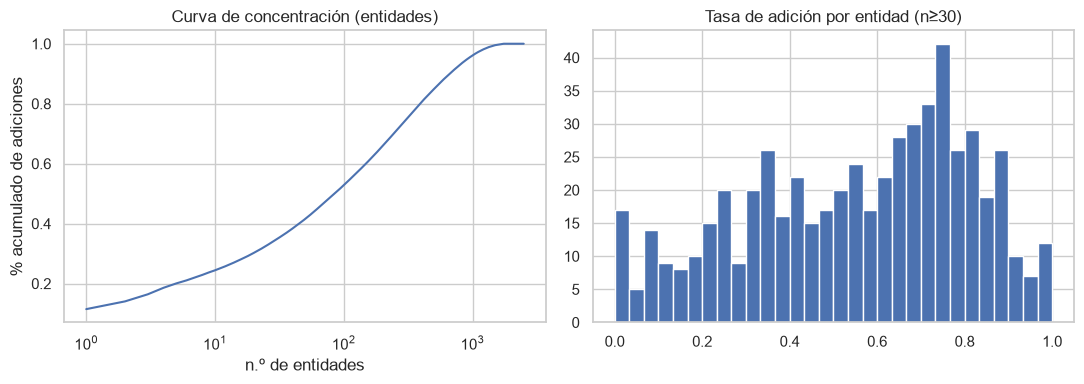

In [10]:
ent = df.groupby("nombre_entidad").agg(contratos=("y", "size"), adic=("y", "sum"), y=("y", "mean")).sort_values("adic", ascending=False)
ent["acum"] = ent.adic.cumsum() / ent.adic.sum()
print(f"Entidades: {len(ent):,}. Top 10 concentran {ent.acum.iloc[min(9, len(ent) - 1)]:.1%} de los contratos con adición; top 100: {ent.acum.iloc[min(99, len(ent) - 1)]:.1%}")
print(ent.head(10)[["contratos", "adic", "y"]].to_string())
big = ent[ent.contratos >= MIN_ENT]
print(f"Entidades con >={MIN_ENT} contratos: {len(big)}. Tasa p10/p50/p90: {big.y.quantile([.1, .5, .9]).round(3).tolist()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(ent) + 1), ent.acum.values); ax[0].set_xscale("log"); ax[0].set_title("Curva de concentración (entidades)")
ax[0].set_xlabel("n.º de entidades"); ax[0].set_ylabel("% acumulado de adiciones")
if len(big): big.y.hist(bins=30, ax=ax[1])
ax[1].set_title(f"Tasa de adición por entidad (n≥{MIN_ENT})")
plt.tight_layout(); plt.savefig(FIG / "07_entidades.png", dpi=150); plt.show()

## 8. Adición en tiempo vs en valor

In [11]:
print(pd.crosstab(df.y_valor, df.y_tiempo, margins=True).to_string())
print("P(valor | tiempo) =", round(df[df.y_tiempo == 1].y_valor.mean(), 3), "| P(tiempo | valor) =", round(df[df.y_valor == 1].y_tiempo.mean(), 3))
pm = df[df.modalidad_de_contratacion.isin(mod.head(6).index)].groupby("modalidad_de_contratacion")[["y_valor", "y_tiempo"]].mean()
print(pm.round(3).to_string())
print(df.groupby("tipo_de_contrato")[["y_valor", "y_tiempo"]].mean().loc[tip.index[:6]].round(3).to_string())

y_tiempo      0      1    All
y_valor                      
0         33956  36348  70304
1          3592   4928   8520
All       37548  41276  78824
P(valor | tiempo) = 0.119 | P(tiempo | valor) = 0.578
                                             y_valor  y_tiempo
modalidad_de_contratacion                                     
Contratación directa                           0.033     0.506
Contratación régimen especial                  0.082     0.435
Contratación régimen especial (con ofertas)    0.086     0.533
Licitación pública Obra Publica                0.113     0.720
Mínima cuantía                                 0.147     0.277
Selección Abreviada de Menor Cuantía           0.145     0.510
                  y_valor  y_tiempo
tipo_de_contrato                   
Obra                0.108     0.524


## 9. Fuga de información: poder predictivo de una sola variable (AUC)
AUC univariada contra `y`. Numéricas: AUC directa. Categóricas: codificación por la tasa del *fold* de entrenamiento (5-fold).
Valores cercanos a 1 = sospecha de fuga; ~0,5 = sin señal.

                 variable                            momento  auc_univariada
           nombre_entidad                              firma           0.775
               plazo_dias                              firma           0.736
          estado_contrato SOSPECHOSA (depende del desenlace)           0.717
                    valor                              firma           0.715
modalidad_de_contratacion                              firma           0.637
             departamento                              firma           0.617
         tipodocproveedor                              firma           0.558
                    orden                              firma           0.554
                      mes                              firma           0.518


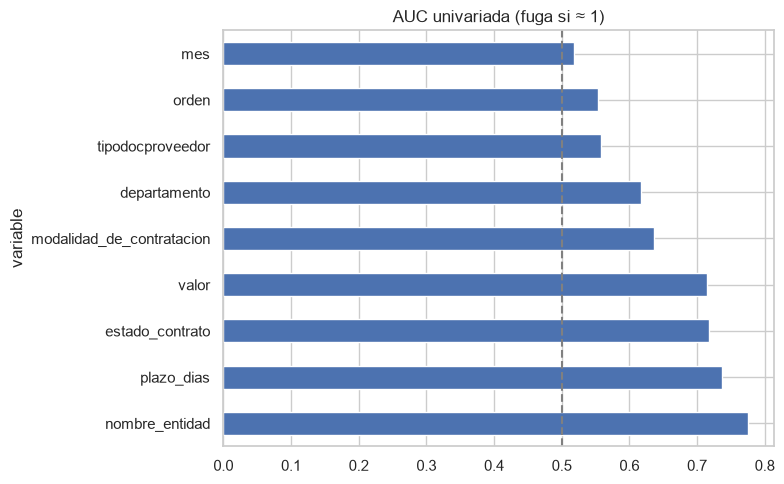

In [12]:
def auc_num(x, y):
    m = x.notna(); s = roc_auc_score(y[m], x[m]); return max(s, 1 - s)

def auc_cat(x, y, k=5):
    x = x.fillna("NA").astype(str).reset_index(drop=True); y = y.reset_index(drop=True); oof = np.zeros(len(x))
    for tr, te in KFold(k, shuffle=True, random_state=0).split(x):
        rate = y.iloc[tr].groupby(x.iloc[tr]).mean()
        oof[te] = x.iloc[te].map(rate).fillna(y.iloc[tr].mean()).values
    return roc_auc_score(y, oof)

if "ultima_actualizacion" in df:
    df["ultima_act_ts"] = pd.to_datetime(df.ultima_actualizacion, errors="coerce").astype("int64") / 1e9
    df.loc[df.ultima_actualizacion.isna(), "ultima_act_ts"] = np.nan
    df["saldo_vig_n"] = num(df.saldo_vigencia)
res = []
for v in [v for v in ["valor", "plazo_dias", "saldo_cdp_n", "mes"] if v in df]:
    res.append((v, "firma", auc_num(df[v], df.y)))
for v in [v for v in ["modalidad_de_contratacion", "tipo_de_contrato", "departamento", "nombre_entidad", "origen_de_los_recursos",
          "condiciones_de_entrega", "tipodocproveedor", "es_pyme", "orden"] if v in df and df[v].nunique() > 1]:
    res.append((v, "firma", auc_cat(df[v], df.y)))
for v in [v for v in ["saldo_vig_n", "ultima_act_ts", "dias_adic"] if v in df and df[v].nunique() > 1]:
    res.append((v, "SOSPECHOSA (posterior a la firma)", auc_num(df[v], df.y)))
res.append(("estado_contrato", "SOSPECHOSA (depende del desenlace)", auc_cat(df.estado_contrato, df.y)))
leak = pd.DataFrame(res, columns=["variable", "momento", "auc_univariada"]).sort_values("auc_univariada", ascending=False)
print(leak.round(3).to_string(index=False))
leak.set_index("variable").auc_univariada.plot.barh(figsize=(8, 5), title="AUC univariada (fuga si ≈ 1)"); plt.axvline(0.5, color="gray", ls="--")
plt.tight_layout(); plt.savefig(FIG / "09_fuga_auc.png", dpi=150); plt.show()

In [13]:
print("Valor mediano del contrato según tenga o no adición en valor:")
print(df.groupby("y_valor").valor.median().to_string())

Valor mediano del contrato según tenga o no adición en valor:
y_valor
0   357,628,237.500
1   456,793,146.500
